# CALCULADORA EÓLICA ENAIR
Debido a que no oppude descarga la calculadora directamente del classroom opte por usar un jupyternootebook para el proyecto final

In [1]:
import pandas as pd
import numpy as np 
import scipy.stats as sp 
import matplotlib.pyplot as plt
from scipy.stats import weibull_min
import math

df = pd.read_csv(r'C:\Users\Moyam\OneDrive\Escritorio\Eolica\ninja_wind_55.0000_3.0000_corrected.csv')

wind_speed = df['wind_speed']

v_media = np.mean(wind_speed)

# SELECCION DE TIPO DE TURBINA
Es importantte definir el tipo de turbina para realizar los calculos de manera correcta

In [3]:
print('Lista de modelos de turbinas:\n1. Excel 1\n2. Excel 6\n3. Skystream 3.7\n4. Gaia 133-11kW\n5. Windspot 3.5\n6. Halbes 1 kW\n7. Aeolos-H 1kW\n8. Lens 1kW\n9. FREEN 20 kW\n10. Zenia 10kW\n11. TN 535 (9.9kW)\n12. E-18 (80kW)\n13. nED100-24\n14. e400nb\n15. KW6')

seleccion_tur = int(input('Por favor seleccione el tipo de turbina: '))

match seleccion_tur:
    case 1:
        fabricante = 'Bergey'
        mod = 'Excel 1'
        pot_nom = 1
        diam_rotor = 2.5
        v_cut_in = 2.5
        v_rat = 11
        v_cut_out = 25
        alt_buje = 18
        nota = 'Datos base: Bergey Excel 1 kW; velocidades típicas para pequeña eólica.'
    case 2:
        fabricante = 'Bergey'
        mod = 'Excel 6'
        pot_nom = 5.5
        diam_rotor = 6.2
        v_cut_in = 2.5
        v_rat = 11
        v_cut_out = 25
        alt_buje = 30
        nota = 'AWEA 5.5 kW @11 m/s, rotor 6.2 m; cut-in 2.5 m/s, sin cut-out declarado, se usa 25 m/s típico.'
    case 3:
        fabricante = 'XZERES'
        mod = 'Skystream 3.7'
        pot_nom = 2.4
        diam_rotor = 3.76
        v_cut_in = 3.5
        v_rat = 11
        v_cut_out = 25
        alt_buje = 20
        nota = 'Capacidad 2.4 kW, rotor 3.72 m; cut-in 3.5 m/s, rated ~13 m/s; cut-out 25 m/s asumido.'
    case 4:
        fabricante = 'Gaia-Wind'
        mod = 'Gaia 133-11kW'
        pot_nom = 11
        diam_rotor = 13
        v_cut_in = 3.5
        v_rat = 11
        v_cut_out = 25
        alt_buje = 18
        nota = 'Potencia 11 kW, rotor 13 m, cut-in 3.5 m/s, shutdown 25 m/s.'
    case 5:
        fabricante = 'Sonkyo Energy'
        mod = 'Windspot 3.5'
        pot_nom = 3.5
        diam_rotor = 4
        v_cut_in = 3
        v_rat = 11
        v_cut_out = 25
        alt_buje = 17
        nota = 'Windspot 3.5 kW, rotor 4 m, start-up 3 m/s, operativa hasta 25 m/s.'
    case 6:
        fabricante = 'Halbes'
        mod = 'Halbes 1 kW'
        pot_nom = 1
        diam_rotor = 2.5
        v_cut_in = 3
        v_rat = 11
        v_cut_out = 25
        alt_buje = 12
        nota = 'Halbes 1 kW; diámetro ~2.5 m, cut-out 25 m/s, resto típico.'
    case 7:
        fabricante = 'Aeolos'
        mod = 'Aeolos-H 1kW'
        pot_nom = 1
        diam_rotor = 3.2
        v_cut_in = 3
        v_rat = 11
        v_cut_out = 25
        alt_buje = 12
        nota = 'Aeolos H 1 kW; rotor ~3.2 m, cut-out 25 m/s, resto típico.'
    case 8:
        fabricante = 'RIAM'
        mod = 'Lens 1kW'
        pot_nom = 1
        diam_rotor = 2
        v_cut_in = 2.5
        v_rat = 10
        v_cut_out = 25
        alt_buje = 10
        nota = 'Turbina con difusor tipo lente; datos generales 1 kW, velocidades típicas.'
    case 9:
        fabricante = 'FREEN'
        mod = 'FREEN 20 kW'
        pot_nom = 20
        diam_rotor = 10
        v_cut_in = 3
        v_rat = 12
        v_cut_out = 25
        alt_buje = 30
        nota = '20 kW small wind; parámetros de velocidad típicos para esta potencia.'
    case 10:
        fabricante = 'Zenia Energy'
        mod = 'Zenia 10kW'
        pot_nom = 10
        diam_rotor = 7
        v_cut_in = 3
        v_rat = 11
        v_cut_out = 25
        alt_buje = 24
        nota = '10 kW small wind; valores de velocidad representativos.'
    case 11:
        fabricante = 'Tozzi Green'
        mod = 'TN 535 (9.9kW)'
        pot_nom = 9.9
        diam_rotor = 5.35
        v_cut_in = 3
        v_rat = 11
        v_cut_out = 25
        alt_buje = 24
        nota = 'TN 535 ~9.9 kW; diámetro 5.35 m, velocidades típicas asumidas.'
    case 12:
        fabricante = 'Enercon'
        mod = 'E-18 (80kW)'
        pot_nom = 80
        diam_rotor = 18
        v_cut_in = 3
        v_rat = 12
        v_cut_out = 25
        alt_buje = 50
        nota = 'Enercon E-18, 80 kW; rotor 18 m, velocidades típicas de eólica media.'
    case 13:
        fabricante = 'Norvento'
        mod = 'nED100-24'
        pot_nom = 100
        diam_rotor = 20
        v_cut_in = 3
        v_rat = 12
        v_cut_out = 25
        alt_buje = 60
        nota = 'nED100-24, 100 kW small wind; parámetros de velocidad genéricos.'
    case 14:
        fabricante = 'Kestrel'
        mod = 'e400nb'
        pot_nom = 2.5
        diam_rotor = 3.8
        v_cut_in = 3
        v_rat = 11
        v_cut_out = 25
        alt_buje = 15
        nota = 'Kestrel e400nb, ~2.5 kW; resto parámetros típicos.'
    case 15:
        fabricante = 'Kingspan'
        mod = 'KW6'
        pot_nom = 6
        diam_rotor = 5.6
        v_cut_in = 3
        v_rat = 11
        v_cut_out = 25
        alt_buje = 15
        nota = 'Kingspan KW6, ~6 kW, diámetro ~5.6 m; velocidades típicas.'
    case 16:
        fabricante = 'Mingyang'
        mod = 'MySE 18.X-20MW'
        pot_nom = 26000
        diam_rotor = 292
        v_cut_in = 3
        v_rat = 8.5
        v_cut_out = 30
        alt_buje = 185
        nota = 'Kingspan KW6, ~6 kW, diámetro ~5.6 m; velocidades típicas.'
print('=' * 100)

print(f'Fabricant: {fabricante}\nModelo: {mod}\nPotencia nominal: {pot_nom} kW\nDiametro del rotor: {diam_rotor} m\nRango operativo: {v_cut_in} a {v_cut_out} m/s\nVelocidad nominal: {v_rat} m/s\nAltura del buje {alt_buje} m\nNota: {nota}')

Lista de modelos de turbinas:
1. Excel 1
2. Excel 6
3. Skystream 3.7
4. Gaia 133-11kW
5. Windspot 3.5
6. Halbes 1 kW
7. Aeolos-H 1kW
8. Lens 1kW
9. FREEN 20 kW
10. Zenia 10kW
11. TN 535 (9.9kW)
12. E-18 (80kW)
13. nED100-24
14. e400nb
15. KW6
Fabricant: Mingyang
Modelo: MySE 18.X-20MW
Potencia nominal: 26000 kW
Diametro del rotor: 292 m
Rango operativo: 3 a 30 m/s
Velocidad nominal: 8.5 m/s
Altura del buje 185 m
Nota: Kingspan KW6, ~6 kW, diámetro ~5.6 m; velocidades típicas.


## VARIABLES
En este apartado definiremos las variables

In [4]:
nombre_sitio = 'Mar del norte'
lat = 55
long = 3
densidad_aire = 1.225
alt_aire_z = 100
vel_viento_z = v_media
alt_aire = int(alt_buje)
vel_viento = float(input('Por favor ingresa la velocidad promedio del viento: '))

print(f'Lugar de estudio: {nombre_sitio}')
print(f'Latitud: {lat}°')
print(f'Longitud: {long}°')
print(f'La densidad del aire es de: {densidad_aire} kg/m^3')
print(f'La altura de referencia es a: {alt_aire_z} m')
print(f'La velocidad del viento en el punto de referencia es de: {vel_viento_z:.3f} m/s')
print(f'La altura del buje esta a: {alt_aire} m')
print(f'La velocidad del viento en el buje es de: {vel_viento} m/s')
print('=' * 100)

Lugar de estudio: Mar del norte
Latitud: 55°
Longitud: 3°
La densidad del aire es de: 1.225 kg/m^3
La altura de referencia es a: 100 m
La velocidad del viento en el punto de referencia es de: 9.964 m/s
La altura del buje esta a: 185 m
La velocidad del viento en el buje es de: 10.71 m/s


# Histograma
Se clasificó los tipos de viento para los calculos energeticos de la turbina por todo el año.

El valor del exponencial de Hellmann es: -0.117

Factor de forma k: 3.067
Factor de escala c: 11.147 m/s


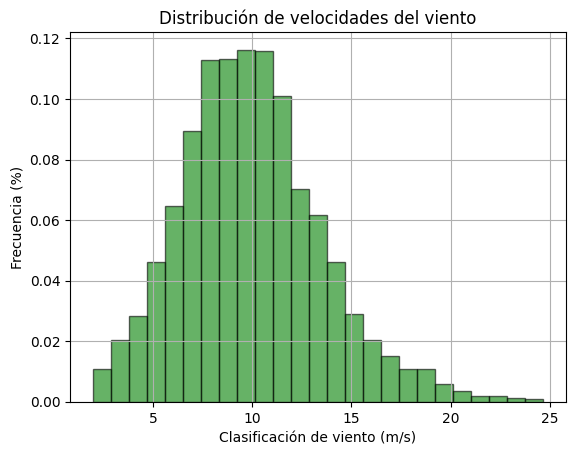

<Figure size 1000x600 with 0 Axes>

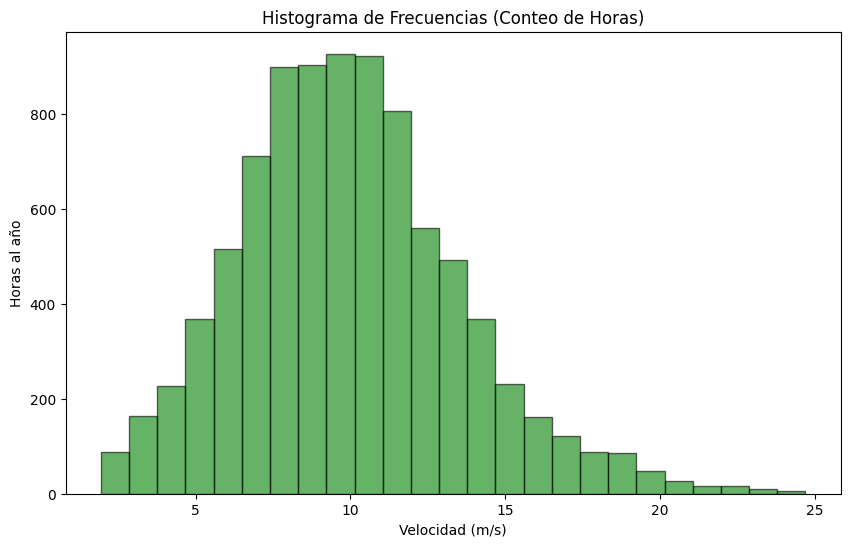

----------------------------------------
   TABLA DE FRECUENCIAS (BIN vs CANTIDAD)
----------------------------------------
 Rango Inicio (m/s)  Rango Fin (m/s)  Horas Totales  Porcentaje (%)
               1.94             2.85           87.0            0.99
               2.85             3.76          163.0            1.86
               3.76             4.67          226.0            2.58
               4.67             5.58          369.0            4.21
               5.58             6.49          515.0            5.88
               6.49             7.40          712.0            8.13
               7.40             8.31          900.0           10.27
               8.31             9.22          903.0           10.31
               9.22            10.13          927.0           10.58
              10.13            11.04          923.0           10.54
              11.04            11.95          806.0            9.20
              11.95            12.86          560.0         

In [5]:
alpha_a = (math.log(vel_viento) - math.log(vel_viento_z)) / (math.log(alt_aire_z) - math.log(alt_aire))

print(f'El valor del exponencial de Hellmann es: {float(alpha_a):.3f}\n')

sigma = np.std(wind_speed)

#print(sigma)
k = (sigma / v_media) ** -1.086

if k > 3.1:
    k = 2
else:
    k = (sigma / v_media) ** -1.086
c = v_media / math.gamma(1 + 1/k)

print(f"Factor de forma k: {k:.3f}")
print(f"Factor de escala c: {c:.3f} m/s")

plt.hist(wind_speed, bins=25, density=True, alpha=0.6, color='g', edgecolor= 'black')
plt.xlabel('Clasificación de viento (m/s)')
plt.ylabel('Frecuencia (%)')
plt.title('Distribución de velocidades del viento')
plt.grid(True)
plt.figure(figsize=(10,6))

plt.figure(figsize=(10, 6))
conteo, divisiones, _ = plt.hist(wind_speed, bins=25, density=False, color='g', alpha=0.6, edgecolor='black')

plt.title("Histograma de Frecuencias (Conteo de Horas)")
plt.xlabel("Velocidad (m/s)")
plt.ylabel("Horas al año")
plt.show()


print("-" * 40)
print("   TABLA DE FRECUENCIAS (BIN vs CANTIDAD)")
print("-" * 40)

datos_hist = pd.DataFrame({
    'Rango Inicio (m/s)': divisiones[:-1],
    'Rango Fin (m/s)': divisiones[1:],  
    'Horas Totales': conteo,
    'Porcentaje (%)': (conteo / conteo.sum()) * 100 
})


datos_hist = datos_hist.round(2)


print(datos_hist.head(25).to_string(index=False))
print("-" * 40)
print(f"Total de horas analizadas: {int(conteo.sum())}")

# AEP
Aquí vamos a calcular la potencia 

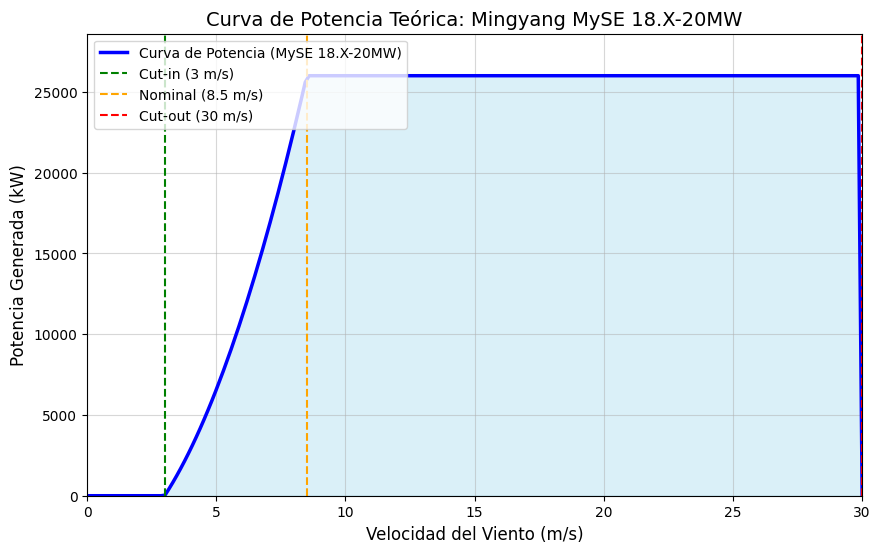

----------------------------------------
RESULTADOS DE LA SIMULACIÓN HORARIA
----------------------------------------
Modelo Turbina: 26000 kW
Velocidad Media del Sitio: 9.96 m/s
Energía Anual Total (AEP): 191124297.81 kWh/año
Factor de Planta: 83.91 %
----------------------------------------


<Figure size 1000x600 with 0 Axes>

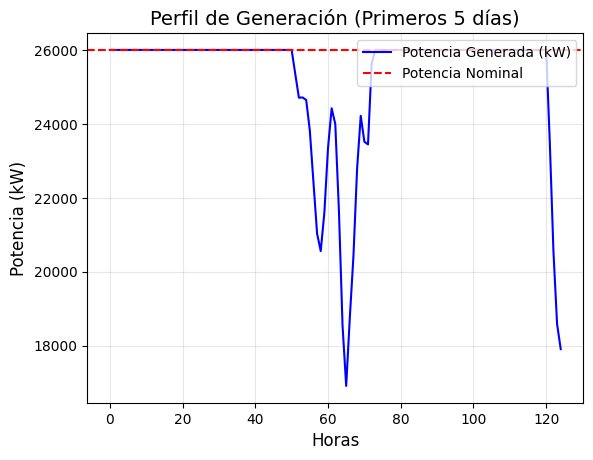

<Figure size 1000x600 with 0 Axes>

In [6]:
consideraciones = [
    (wind_speed < v_cut_in),
    (wind_speed >= v_cut_in) & (wind_speed < v_rat),
    (wind_speed >= v_rat) & (wind_speed < v_cut_out),
    (wind_speed >= v_cut_out)
]

curva_ascenso = pot_nom * ((wind_speed**2 - v_cut_in**2) / (v_rat**2 - v_cut_in**2))

elecciones = [
    0,
    curva_ascenso,
    pot_nom,
    0
]

df['potencia_kW'] = np.select(consideraciones, elecciones)

v_graf = np.linspace(0, 30, 200)
con_graf = [
    (v_graf < v_cut_in),
    (v_graf >= v_cut_in) & (v_graf < v_rat),
    (v_graf >= v_rat) & (v_graf < v_cut_out),
    (v_graf >= v_cut_out)
]

curva_ascenso_graf = pot_nom * ((v_graf**2 - v_cut_in**2) / (v_rat**2 - v_cut_in**2))

elecciones_graf = [
    0,
    curva_ascenso_graf,
    pot_nom,
    0
]

p_graf = np.select(con_graf, elecciones_graf)
plt.figure(figsize=(10, 6))
plt.plot(v_graf, p_graf, color='blue', linewidth=2.5, label=f'Curva de Potencia ({mod})')
plt.fill_between(v_graf, p_graf, color='skyblue', alpha=0.3)
plt.axvline(x=v_cut_in, color='green', linestyle='--', label=f'Cut-in ({v_cut_in} m/s)')
plt.axvline(x=v_rat, color='orange', linestyle='--', label=f'Nominal ({v_rat} m/s)')
plt.axvline(x=v_cut_out, color='red', linestyle='--', label=f'Cut-out ({v_cut_out} m/s)')
plt.title(f"Curva de Potencia Teórica: {fabricante} {mod}", fontsize=14)
plt.xlabel("Velocidad del Viento (m/s)", fontsize=12)
plt.ylabel("Potencia Generada (kW)", fontsize=12)
plt.legend(loc='upper left')
plt.grid(True, alpha=0.5)
plt.xlim(0, 30)
plt.ylim(0, pot_nom * 1.1)

plt.show()

aep_total = df['potencia_kW'].sum()

horas_anio = len(wind_speed)
energia_teorica_maxima = pot_nom * horas_anio
factor_planta = (aep_total / energia_teorica_maxima) * 100

print("-" * 40)
print(f"RESULTADOS DE LA SIMULACIÓN HORARIA")
print("-" * 40)
print(f"Modelo Turbina: {pot_nom} kW")
print(f"Velocidad Media del Sitio: {v_media:.2f} m/s")
print(f"Energía Anual Total (AEP): {aep_total:.2f} kWh/año")
print(f"Factor de Planta: {factor_planta:.2f} %")
print("-" * 40)

plt.plot(df['potencia_kW'][:125], label='Potencia Generada (kW)', color='blue')
plt.axhline(y=pot_nom, color='r', linestyle='--', label='Potencia Nominal')
plt.title("Perfil de Generación (Primeros 5 días)", fontsize=14)
plt.xlabel("Horas", fontsize=12)
plt.ylabel("Potencia (kW)", fontsize=12)
plt.legend(loc='upper right')
plt.grid(True, alpha=0.3)
plt.figure(figsize = (10, 6))

# Base de datos masiva


Iniciando simulación masiva...
Eficiencia Global del Sistema: 93.16%
Pérdidas Totales estimadas: 6.84%
--------------------------------------------------
--------------------------------------------------
        Modelo  P_Nominal  AEP_Bruta_kWh  AEP_Neta_kWh  Factor_Planta_Neto_%
MySE 18.X-20MW    26000.0    191124298.0   178049102.0                  78.2
        nED100      100.0       544315.0      507078.0                  57.9
   E-18 (80kW)       80.0       435452.0      405662.0                  57.9
    FREEN 20kW       20.0       108863.0      101416.0                  57.9
      Gaia 133       11.0        65431.0       60955.0                  63.3
    Zenia 10kW       10.0        60256.0       56133.0                  64.1
        TN 535        9.9        59653.0       55572.0                  64.1
           KW6        6.0        36153.0       33680.0                  64.1
       Excel 6        5.5        33492.0       31200.0                  64.8
  Windspot 3.5        3.5

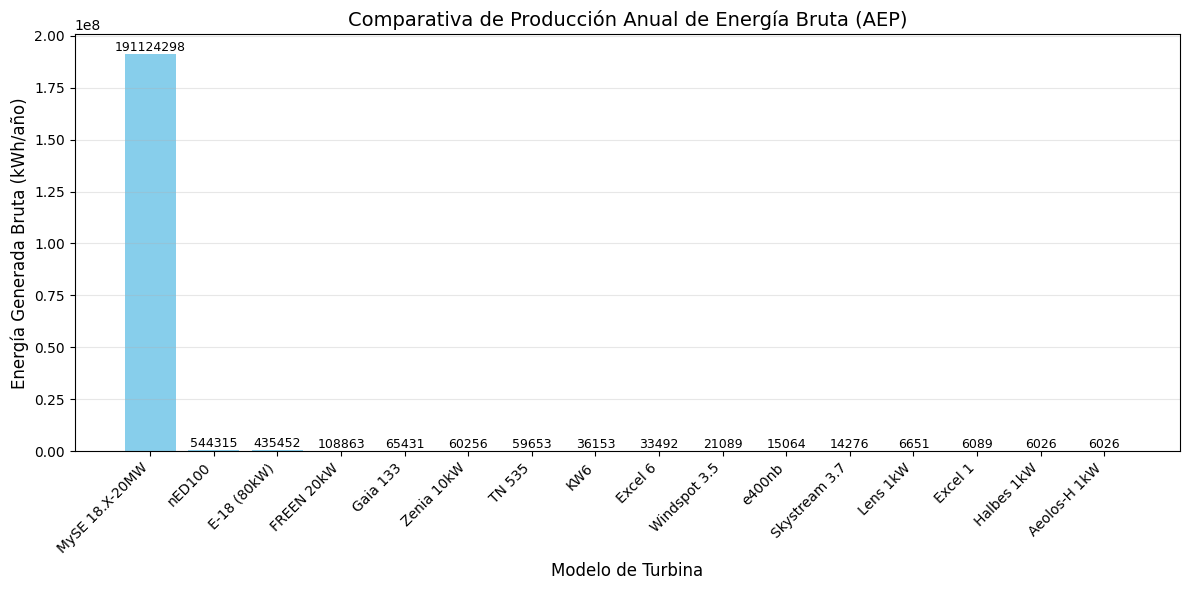

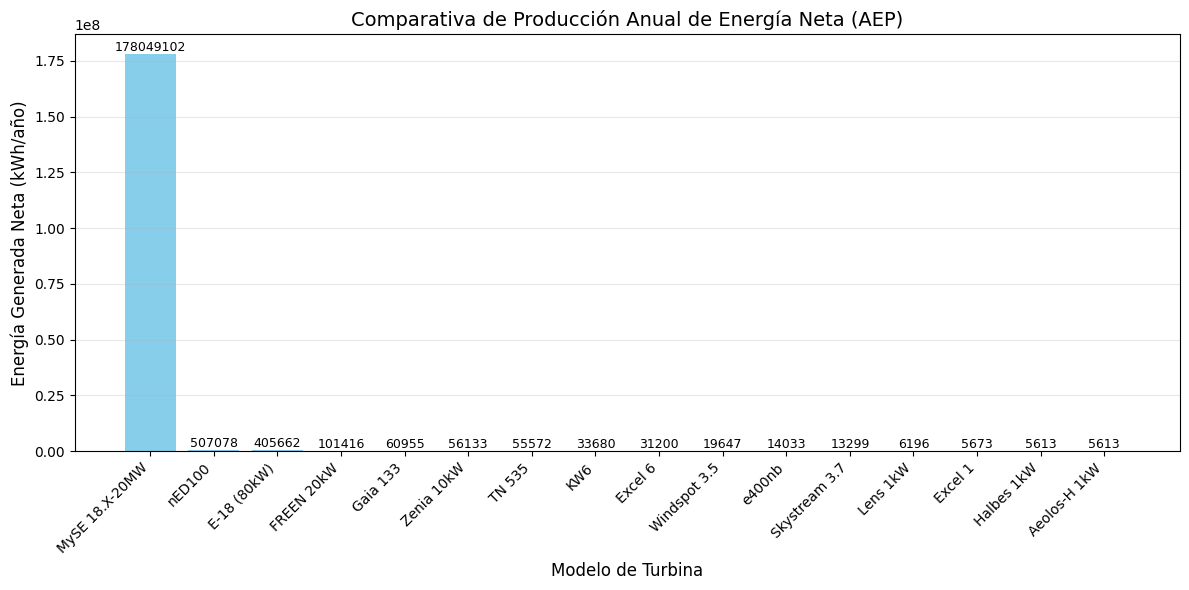

In [129]:
# BASE DE DATOS DE TUS 15 MODELOS
base_datos_turbinas = [
    {'id': 1, 'fabricante': 'Bergey', 'modelo': 'Excel 1', 'p_nom': 1, 'diam': 2.5, 'v_in': 2.5, 'v_rat': 11, 'v_out': 25, 'h_buje': 18},
    {'id': 2, 'fabricante': 'Bergey', 'modelo': 'Excel 6', 'p_nom': 5.5, 'diam': 6.2, 'v_in': 2.5, 'v_rat': 11, 'v_out': 25, 'h_buje': 30},
    {'id': 3, 'fabricante': 'XZERES', 'modelo': 'Skystream 3.7', 'p_nom': 2.4, 'diam': 3.76, 'v_in': 3.5, 'v_rat': 11, 'v_out': 25, 'h_buje': 20},
    {'id': 4, 'fabricante': 'Gaia-Wind', 'modelo': 'Gaia 133', 'p_nom': 11, 'diam': 13, 'v_in': 3.5, 'v_rat': 11, 'v_out': 25, 'h_buje': 18},
    {'id': 5, 'fabricante': 'Sonkyo', 'modelo': 'Windspot 3.5', 'p_nom': 3.5, 'diam': 4, 'v_in': 3, 'v_rat': 11, 'v_out': 25, 'h_buje': 17},
    {'id': 6, 'fabricante': 'Halbes', 'modelo': 'Halbes 1kW', 'p_nom': 1, 'diam': 2.5, 'v_in': 3, 'v_rat': 11, 'v_out': 25, 'h_buje': 12},
    {'id': 7, 'fabricante': 'Aeolos', 'modelo': 'Aeolos-H 1kW', 'p_nom': 1, 'diam': 3.2, 'v_in': 3, 'v_rat': 11, 'v_out': 25, 'h_buje': 12},
    {'id': 8, 'fabricante': 'RIAM', 'modelo': 'Lens 1kW', 'p_nom': 1, 'diam': 2, 'v_in': 2.5, 'v_rat': 10, 'v_out': 25, 'h_buje': 10},
    {'id': 9, 'fabricante': 'FREEN', 'modelo': 'FREEN 20kW', 'p_nom': 20, 'diam': 10, 'v_in': 3, 'v_rat': 12, 'v_out': 25, 'h_buje': 30},
    {'id': 10, 'fabricante': 'Zenia', 'modelo': 'Zenia 10kW', 'p_nom': 10, 'diam': 7, 'v_in': 3, 'v_rat': 11, 'v_out': 25, 'h_buje': 24},
    {'id': 11, 'fabricante': 'Tozzi', 'modelo': 'TN 535', 'p_nom': 9.9, 'diam': 5.35, 'v_in': 3, 'v_rat': 11, 'v_out': 25, 'h_buje': 24},
    {'id': 12, 'fabricante': 'Enercon', 'modelo': 'E-18 (80kW)', 'p_nom': 80, 'diam': 18, 'v_in': 3, 'v_rat': 12, 'v_out': 25, 'h_buje': 50},
    {'id': 13, 'fabricante': 'Norvento', 'modelo': 'nED100', 'p_nom': 100, 'diam': 20, 'v_in': 3, 'v_rat': 12, 'v_out': 25, 'h_buje': 60},
    {'id': 14, 'fabricante': 'Kestrel', 'modelo': 'e400nb', 'p_nom': 2.5, 'diam': 3.8, 'v_in': 3, 'v_rat': 11, 'v_out': 25, 'h_buje': 15},
    {'id': 15, 'fabricante': 'Kingspan', 'modelo': 'KW6', 'p_nom': 6, 'diam': 5.6, 'v_in': 3, 'v_rat': 11, 'v_out': 25, 'h_buje': 15},
    {'id': 15, 'fabricante': 'Mingyang', 'modelo': 'MySE 18.X-20MW', 'p_nom': 26000, 'diam': 292, 'v_in': 3, 'v_rat': 8.5, 'v_out': 25, 'h_buje': 185}
]

v_sitio = df['wind_speed']

print("Iniciando simulación masiva...")

eff_disponibilidad = 0.97  # 3% tiempo parada por mantenimiento
eff_electrica      = 0.98  # 2% pérdida en cables y trafo
eff_ambiental      = 0.98  # 2% por suciedad en palas / turbulencia
eff_estela         = 1.00  # 0% si es una sola turbina aislada

FACTOR_PERDIDAS = eff_disponibilidad * eff_electrica * eff_ambiental * eff_estela
print(f"Eficiencia Global del Sistema: {FACTOR_PERDIDAS:.2%}")
print(f"Pérdidas Totales estimadas: {(1 - FACTOR_PERDIDAS):.2%}")
print("-" * 50)

resultados_comparativos = []

for t in base_datos_turbinas:
    
    v_in = t['v_in']
    v_rat = t['v_rat']
    v_out = t['v_out']
    p_nom = t['p_nom']
    
    condiciones = [
        (v_sitio < v_in),
        (v_sitio >= v_in) & (v_sitio < v_rat),
        (v_sitio >= v_rat) & (v_sitio < v_out),
        (v_sitio >= v_out)
    ]
    
    curva = p_nom * ((v_sitio**2 - v_in**2) / (v_rat**2 - v_in**2))
    
    valores = [0, curva, p_nom, 0]
    
    potencia_generada_bruta = np.select(condiciones, valores)
    
    aep_anual_bruta = potencia_generada_bruta.sum()
    
    aep_neta = aep_anual_bruta * FACTOR_PERDIDAS
    
    energia_max = p_nom * len(v_sitio)
    fp_neto = (aep_neta / energia_max) * 100
    
    resultados_comparativos.append({
        'Modelo': t['modelo'],
        'P_Nominal': p_nom,
        'AEP_Bruta_kWh': round(aep_anual_bruta, 0),
        'AEP_Neta_kWh': round(aep_neta, 0),     # ¡Este es el dato que importa!
        'Factor_Planta_Neto_%': round(fp_neto, 1)
    })

df_resultados = pd.DataFrame(resultados_comparativos).sort_values(by='AEP_Neta_kWh', ascending=False)

print("-" * 50)
print(df_resultados.to_string(index=False)) # tabla kul
print("-" * 50)

plt.figure(figsize=(12, 6))

barras = plt.bar(df_resultados['Modelo'], df_resultados['AEP_Bruta_kWh'], color='skyblue')

plt.title('Comparativa de Producción Anual de Energía Bruta (AEP)', fontsize=14)
plt.ylabel('Energía Generada Bruta (kWh/año)', fontsize=12)
plt.xlabel('Modelo de Turbina', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', alpha=0.3)

for barra in barras:
    altura = barra.get_height()
    plt.text(barra.get_x() + barra.get_width()/2., altura,
             f'{int(altura)}',
             ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 6))

barras = plt.bar(df_resultados['Modelo'], df_resultados['AEP_Neta_kWh'], color='skyblue')

plt.title('Comparativa de Producción Anual de Energía Neta (AEP)', fontsize=14)
plt.ylabel('Energía Generada Neta (kWh/año)', fontsize=12)
plt.xlabel('Modelo de Turbina', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', alpha=0.3)

for barra in barras:
    altura = barra.get_height()
    plt.text(barra.get_x() + barra.get_width()/2., altura,
             f'{int(altura)}',
             ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()